# Uczenie Maszynowe – Lista 2
## Modele liniowe: regresja liniowa i logistyczna

Celem ćwiczenia jest zrozumienie fundamentów uczenia maszynowego poprzez analizę modeli liniowych. Zbadamy:
- **Regresję liniową** z regularyzacją Ridge i LASSO (zbiór WINE)
- **Regresję logistyczną** na niezbalansowanym zbiorze bankructw (Polish Bankruptcy)
- **SVM** – klasyfikator z jądrem liniowym i RBF

## Importy i konfiguracja

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, LogisticRegression
)
from sklearn.svm import SVC
from sklearn.metrics import (
    mean_squared_error, r2_score,
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score, accuracy_score,
    roc_curve, auc, ConfusionMatrixDisplay
)
from scipy.io import arff

# Zadanie 1: Regresja i regularyzacja (zbiór WINE)

Zbiór WINE zawiera dane chemiczne 178 próbek wina z trzech odmian. Zamiast klasyfikować odmiane, postaramy się **przewidzieć zawartość alkoholu** (`alcohol`) na podstawie pozostałych cech.

## Zadanie 1.1 – Załadowanie zbioru WINE i wybór zmiennej docelowej

In [2]:
wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)

print('Cechy zbioru WINE:')
print(wine.feature_names)
print(f'\nRozmiar zbioru: {df_wine.shape}')
df_wine.describe().round(2)

Cechy zbioru WINE:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Rozmiar zbioru: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [3]:
TARGET = 'alcohol'

X = df_wine.drop(columns=[TARGET]).values
y = df_wine[TARGET].values
feature_names = [f for f in wine.feature_names if f != TARGET]

print(f'Zmienna docelowa: {TARGET}')
print(f'Liczba cech predykcyjnych: {X.shape[1]}')
print(f'Zakres {TARGET}: [{y.min():.2f}, {y.max():.2f}]')

Zmienna docelowa: alcohol
Liczba cech predykcyjnych: 12
Zakres alcohol: [11.03, 14.83]


## Zadanie 1.2 – Podział na zbior treningowy i testowy

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1,
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Zbiór treningowy: {X_train.shape[0]} próbek')
print(f'Zbiór testowy:    {X_test.shape[0]} próbek')
print('Dane przeskalowane (StandardScaler) – wymagane dla Ridge/LASSO.')

Zbiór treningowy: 142 próbek
Zbiór testowy:    36 próbek
Dane przeskalowane (StandardScaler) – wymagane dla Ridge/LASSO.


## Zadanie 1.3 – Regresja liniowa (OLS – metoda najmniejszych kwadratów)

In [6]:
lr = LinearRegression()
lr.fit(X_train_sc, y_train)

y_pred_train = lr.predict(X_train_sc)
y_pred_test  = lr.predict(X_test_sc)

print('Regresja liniowa (OLS)')
print(f'Train R2:  {r2_score(y_train, y_pred_train):.4f}')
print(f'Test  R2:  {r2_score(y_test,  y_pred_test):.4f}')
print(f'Train MSE: {mean_squared_error(y_train, y_pred_train):.4f}')
print(f'Test  MSE: {mean_squared_error(y_test,  y_pred_test):.4f}')

Regresja liniowa (OLS)
Train R2:  0.5842
Test  R2:  0.5946
Train MSE: 0.2668
Test  MSE: 0.2872


## Zadanie 1.4 – Wizualizacja metryk R2 i MSE

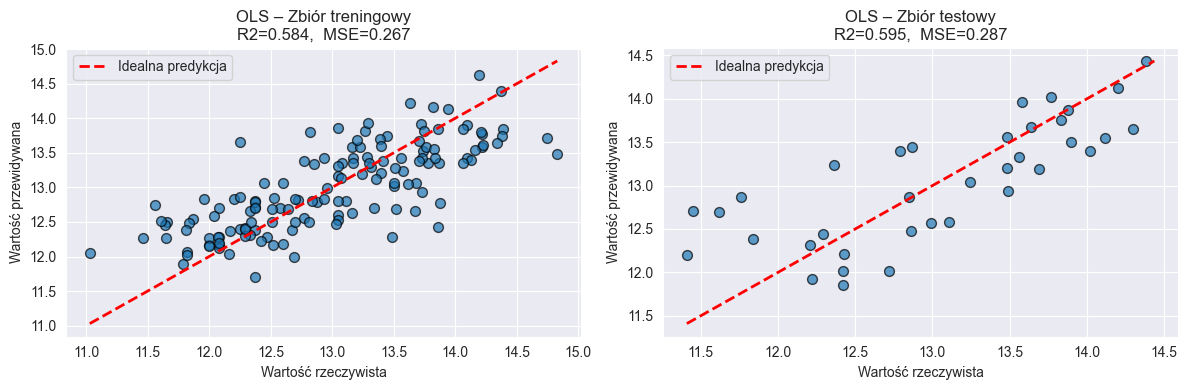

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (y_true, y_pred, title) in zip(axes, [
    (y_train, y_pred_train, 'Zbiór treningowy'),
    (y_test,  y_pred_test,  'Zbiór testowy')
]):
    ax.scatter(y_true, y_pred, alpha=0.7, edgecolors='k', s=50)
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    ax.plot([lo, hi], [lo, hi], 'r--', lw=2, label='Idealna predykcja')
    ax.set_xlabel('Wartość rzeczywista')
    ax.set_ylabel('Wartość przewidywana')
    r2 = r2_score(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    ax.set_title(f'OLS – {title}\nR2={r2:.3f},  MSE={mse:.3f}')
    ax.legend()

plt.tight_layout()
plt.show()

## Zadanie 1.5 – Ridge i LASSO: ścieżki regularyzacji

> **Dlaczego skalowanie jest krytyczne dla Ridge/LASSO?**  
> Regularyzacja karze za wielkość współczynników. Cechy w różnych skalach (np. jedna w gramach ~1000, inna w procentach ~0-1) dostają niesprawiedliwe kary. StandardScaler wyrównuje skale, dzięki czemu wspołczynniki są porównywalne i regularyzacja działa sensownie.

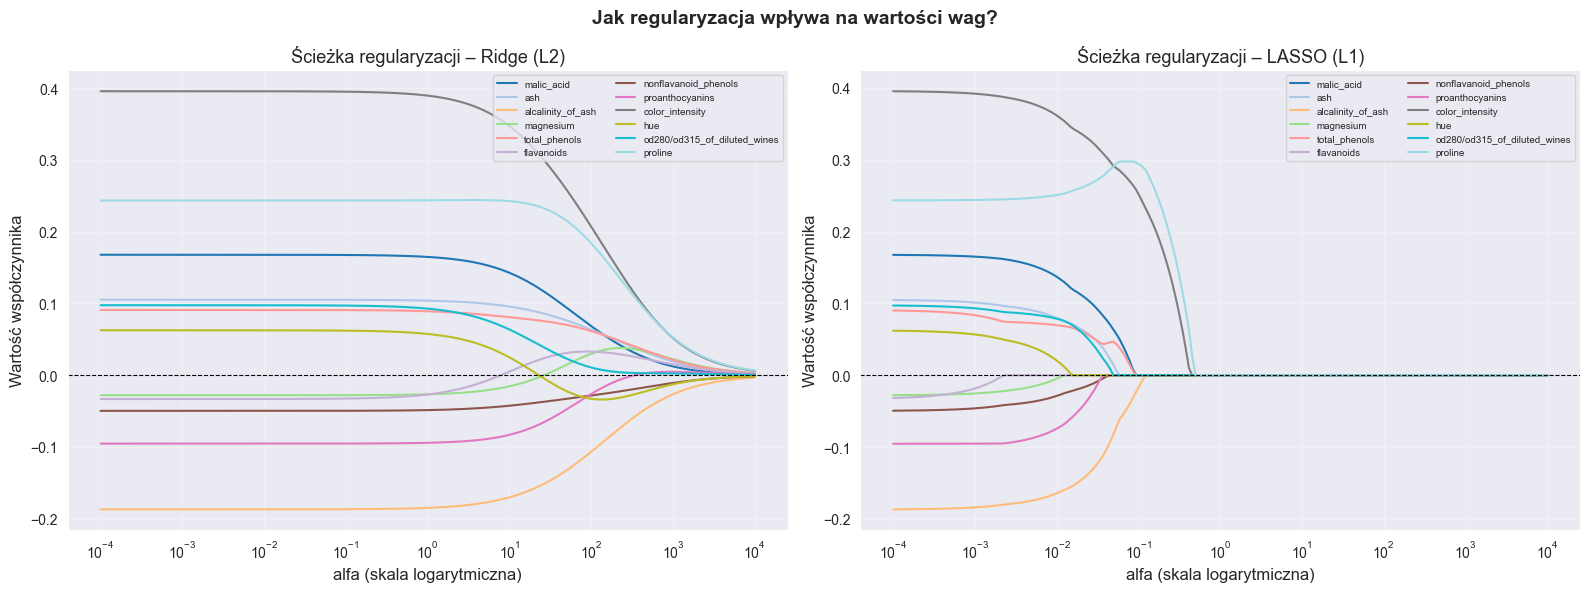

Ridge: współczynniki maleją płynnie do 0, ale nigdy nie osiagają dokładnie 0.
LASSO: współczynniki zerują się ostro dla dużych alfa – dokonuje selekcji cech.


In [12]:
alphas = np.logspace(-4, 4, 200)

ridge_coefs = np.array([Ridge(alpha=a).fit(X_train_sc, y_train).coef_ for a in alphas])
lasso_coefs = np.array([
    Lasso(alpha=a, max_iter=10000).fit(X_train_sc, y_train).coef_ for a in alphas
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(feature_names)))

for i, (name, col) in enumerate(zip(feature_names, colors)):
    ax1.plot(alphas, ridge_coefs[:, i], color=col, label=name, lw=1.5)
    ax2.plot(alphas, lasso_coefs[:, i], color=col, label=name, lw=1.5)

for ax, title in [(ax1, 'Ridge (L2)'), (ax2, 'LASSO (L1)')]:
    ax.set_xscale('log')
    ax.axhline(0, color='black', lw=0.8, ls='--')
    ax.set_xlabel('alfa (skala logarytmiczna)', fontsize=12)
    ax.set_ylabel('Wartość współczynnika', fontsize=12)
    ax.set_title(f'Ścieżka regularyzacji – {title}', fontsize=13)
    ax.legend(loc='upper right', fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)

plt.suptitle('Jak regularyzacja wpływa na wartości wag?', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Ridge: współczynniki maleją płynnie do 0, ale nigdy nie osiagają dokładnie 0.')
print('LASSO: współczynniki zerują się ostro dla dużych alfa – dokonuje selekcji cech.')

In [13]:
# Porównanie wyników dla rożnych wartości alfa
test_alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

print(f'{"alfa":>8} | {"Ridge R2 (test)":>16} | {"LASSO R2 (test)":>16} | {"LASSO niezerowe wagi":>18}')

for a in test_alphas:
    r = Ridge(alpha=a).fit(X_train_sc, y_train)
    l = Lasso(alpha=a, max_iter=10000).fit(X_train_sc, y_train)
    r2_r = r2_score(y_test, r.predict(X_test_sc))
    r2_l = r2_score(y_test, l.predict(X_test_sc))
    n_nz = np.sum(np.abs(l.coef_) > 1e-4)
    print(f'{a:>8.3f} | {r2_r:>16.4f} | {r2_l:>16.4f} | {n_nz:>18d}')

    alfa |  Ridge R2 (test) |  LASSO R2 (test) | LASSO niezerowe wagi
   0.001 |           0.5946 |           0.5982 |                 12
   0.010 |           0.5946 |           0.6175 |                 11
   0.100 |           0.5948 |           0.6185 |                  3
   1.000 |           0.5964 |          -0.0023 |                  0
  10.000 |           0.6051 |          -0.0023 |                  0
 100.000 |           0.5561 |          -0.0023 |                  0


## Zadanie 1.6 – Walidacja krzyżowa do wyznaczenia optymalnego alfa

> **Dlaczego k-fold CV jest lepsze niz pojedyńczy podział?**
> Pojedynczy podział train/test jest losowy – wynik zależy od tego, które próbki trafiły do testu. Dla małego zbioru (178 próbek w WINE) może to dawać niestabilne oszacowania. CV uśrednia wyniki po k różnych podziałach, co daje bardziej wiarygodną ocene jakości modelu i pozwala lepiej dobrać hiperparametry.

In [14]:
alphas_cv = np.logspace(-4, 4, 100)

ridge_cv = RidgeCV(alphas=alphas_cv, cv=10).fit(X_train_sc, y_train)
lasso_cv = LassoCV(alphas=alphas_cv, cv=10, max_iter=10000, random_state=1).fit(X_train_sc, y_train)

print(f'Optymalne alfa (RidgeCV):  {ridge_cv.alpha_:.6f}')
print(f'Optymalne alfa (LassoCV):  {lasso_cv.alpha_:.6f}')

ridge_manual = Ridge(alpha=1.0).fit(X_train_sc, y_train)
lasso_manual = Lasso(alpha=1.0, max_iter=10000).fit(X_train_sc, y_train)

print('\nPorównanie ręcznie ustawiona alfa vs CV-optymalny alfa')
print(f'{"Model":<20} {"alfa":<10} {"R2 (test)":<12} {"MSE (test)"}')

for name, model, alpha_val in [
    ('Ridge alfa=1.0', ridge_manual, 1.0),
    ('Ridge CV', ridge_cv, ridge_cv.alpha_),
    ('LASSO alfa=1.0', lasso_manual, 1.0),
    ('LASSO CV', lasso_cv, lasso_cv.alpha_),
]:
    yp = model.predict(X_test_sc)
    print(f'{name:<20} {alpha_val:<10.4f} {r2_score(y_test, yp):<12.4f} {mean_squared_error(y_test, yp):.4f}')

Optymalne alfa (RidgeCV):  31.257158
Optymalne alfa (LassoCV):  0.026561

Porównanie ręcznie ustawiona alfa vs CV-optymalny alfa
Model                alfa       R2 (test)    MSE (test)
Ridge alfa=1.0       1.0000     0.5964       0.2860
Ridge CV             31.2572    0.6039       0.2807
LASSO alfa=1.0       1.0000     -0.0023      0.7101
LASSO CV             0.0266     0.6338       0.2595


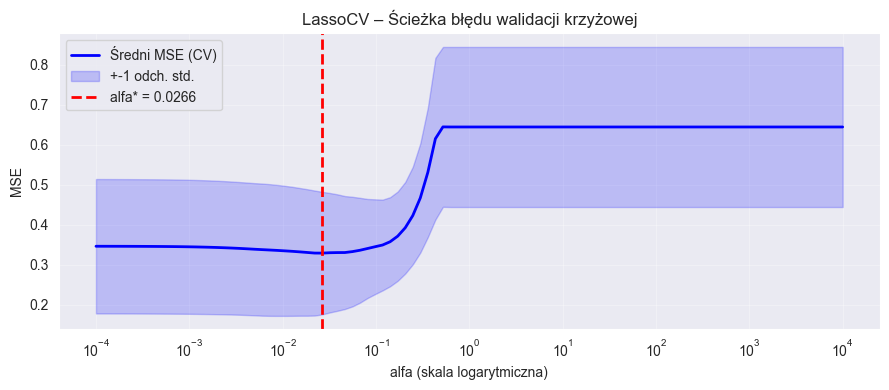

In [15]:
# Ścieżka CV dla LASSO
fig, ax = plt.subplots(figsize=(9, 4))
mse_mean = lasso_cv.mse_path_.mean(axis=-1)
mse_std  = lasso_cv.mse_path_.std(axis=-1)

ax.semilogx(lasso_cv.alphas_, mse_mean, 'b-', lw=2, label='Średni MSE (CV)')
ax.fill_between(lasso_cv.alphas_, mse_mean - mse_std, mse_mean + mse_std,
                alpha=0.2, color='blue', label='+-1 odch. std.')
ax.axvline(lasso_cv.alpha_, color='red', ls='--', lw=2,
           label=f'alfa* = {lasso_cv.alpha_:.4f}')
ax.set_xlabel('alfa (skala logarytmiczna)')
ax.set_ylabel('MSE')
ax.set_title('LassoCV – Ścieżka błędu walidacji krzyżowej')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Zadanie 2: Klasyfikacja probabilistyczna (zbiór Bankruptcy)

Zbiór Polish Companies Bankruptcy zawiera dane finansowe polskich firm. Celem jest przewidzenie bankructwa (klasa `1`) lub jego braku (klasa `0`). Zbiór jest **silnie niezbalansowany** – bankrutujace firmy stanowia mniejszość.

## Zadanie 2.1 – Załadowanie zbioru bankructw

In [16]:
def load_arff(filepath: str) -> pd.DataFrame:
    """Wczytuje plik .arff i zwraca go jako DataFrame."""
    data, meta = arff.loadarff(filepath)
    df = pd.DataFrame(data)
    df['class'] = df['class'].str.decode('utf-8').astype(int)
    return df

files = [
    '1year.arff',
    # '2year.arff',
    # '3year.arff',
    # '4year.arff',
    # '5year.arff',
]

dfs = []
for f in files:
    df_tmp = load_arff(f'polish_companies_bankruptcy_data/{f}')
    dfs.append(df_tmp)

df_bk = pd.concat(dfs, ignore_index=True)

print(f'Rozmiar zbioru: {df_bk.shape}')
print(f'\nRozkład klas:')
print(df_bk['class'].value_counts())
print(f'\nProporcja bankructw: {df_bk["class"].mean()*100:.2f}%')
print(f'Brakujące wartości: {df_bk.isnull().sum().sum()}')

Rozmiar zbioru: (7027, 65)

Rozkład klas:
class
0    6756
1     271
Name: count, dtype: int64

Proporcjaa bankructw: 3.86%
Brakujące wartości: 5835


In [17]:
# Przygotowanie danych, usuwamanie braków
df_bk_clean = df_bk.dropna()
print(f'Rozmiar po usunieciu braków: {df_bk_clean.shape}')
print(f'Rozkład klas po czyszczeniu:')
print(df_bk_clean['class'].value_counts())

X_bk = df_bk_clean.drop(columns=['class']).values
y_bk = df_bk_clean['class'].values
feature_names_bk = [c for c in df_bk_clean.columns if c != 'class']

# Podział stratyfikowany (zachowujemy proporcje klas)
X_bk_tr, X_bk_te, y_bk_tr, y_bk_te = train_test_split(
    X_bk, y_bk, test_size=0.2, random_state=1, stratify=y_bk
)

sc_bk = StandardScaler()
X_bk_tr_sc = sc_bk.fit_transform(X_bk_tr)
X_bk_te_sc  = sc_bk.transform(X_bk_te)

print(f'\nTreningowy: {X_bk_tr.shape[0]} | Testowy: {X_bk_te.shape[0]}')

Rozmiar po usunieciu braków: (3194, 65)
Rozkład klas po czyszczeniu:
class
0    3164
1      30
Name: count, dtype: int64

Treningowy: 2555 | Testowy: 639


## Zadanie 2.2 – Regresja logistyczna z StandardScaler

In [18]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=1,
)
log_reg.fit(X_bk_tr_sc, y_bk_tr)

y_bk_pred = log_reg.predict(X_bk_te_sc)

## Zadanie 2.3 – Macierz pomyłek i metryki jakości

### Interpretacja metryk:
- **Accuracy** – udział poprawnie sklasyfikowanych próbek. Mylący przy niezbalansowanych danych (model mówiący zawsze '0' może mieć 95% accuracy!)
- **Precision** – mówi ile ze wszystkich przewidzianych bankrutów, faktycznie zbankrutowało. Ważna gdy koszt fałszywego alarmu jest wysoki.
- **Recall (czułość)** – mówi ile ze wszystkich faktycznych bankrutów, wykryliśmy. Kluczowa gdy, nie chcemy przeoczyć bankruta.
- **F1** – średnia harmoniczna Precision i Recall. Dobry kompromis przy niezbalansowanych danych.

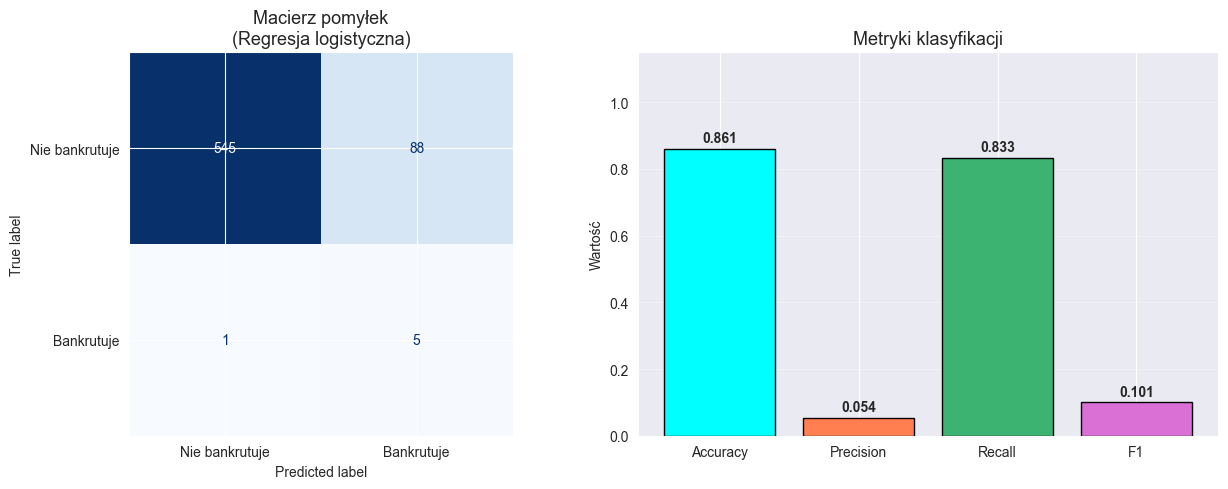


Raport klasyfikacji
                precision    recall  f1-score   support

Nie bankrutuje       1.00      0.86      0.92       633
    Bankrutuje       0.05      0.83      0.10         6

      accuracy                           0.86       639
     macro avg       0.53      0.85      0.51       639
  weighted avg       0.99      0.86      0.92       639



In [21]:
cm = confusion_matrix(y_bk_te, y_bk_pred)

_, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Nie bankrutuje', 'Bankrutuje'])
disp.plot(ax=ax1, colorbar=False, cmap='Blues')
ax1.set_title('Macierz pomyłek\n(Regresja logistyczna)', fontsize=13)

metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1']
metrics_vals  = [
    accuracy_score(y_bk_te, y_bk_pred),
    precision_score(y_bk_te, y_bk_pred, zero_division=0),
    recall_score(y_bk_te, y_bk_pred, zero_division=0),
    f1_score(y_bk_te, y_bk_pred, zero_division=0)
]
bar_colors = ['cyan', 'coral', 'mediumseagreen', 'orchid']
bars = ax2.bar(metrics_names, metrics_vals, color=bar_colors, edgecolor='black')
for bar, val in zip(bars, metrics_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold')
ax2.set_ylim(0, 1.15)
ax2.set_title('Metryki klasyfikacji', fontsize=13)
ax2.set_ylabel('Wartość')
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print('\nRaport klasyfikacji')
print(classification_report(y_bk_te, y_bk_pred, target_names=['Nie bankrutuje', 'Bankrutuje']))

### Interpretacja wag modelu – które cechy mają największy wpływ?

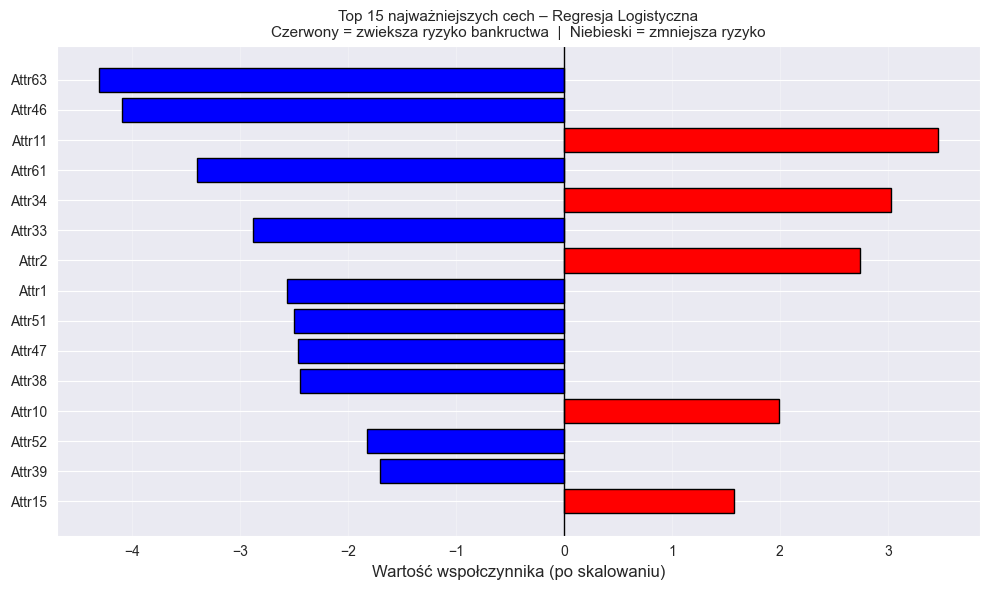

Cechy zwiększające ryzyko bankructwa (waga > 0):
 cecha     waga
Attr11 3.464832
Attr34 3.033399
 Attr2 2.743725
Attr10 1.991203
Attr15 1.572336

Cechy zmniejszające ryzyko bankructwa (waga < 0):
 cecha      waga
Attr63 -4.306467
Attr46 -4.095950
Attr61 -3.392744
Attr33 -2.878028
 Attr1 -2.559991


In [20]:
coef = log_reg.coef_[0]
coef_df = pd.DataFrame({'cecha': feature_names_bk, 'waga': coef})
coef_df = coef_df.reindex(coef_df['waga'].abs().sort_values(ascending=False).index)

top_n = 15
top_df = coef_df.head(top_n)

fig, ax = plt.subplots(figsize=(10, 6))
colors_bar = ['red' if w > 0 else 'blue' for w in top_df['waga']]
ax.barh(top_df['cecha'], top_df['waga'], color=colors_bar, edgecolor='black')
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Wartość wspołczynnika (po skalowaniu)', fontsize=12)
ax.set_title(
    f'Top {top_n} najważniejszych cech – Regresja Logistyczna\n'
    'Czerwony = zwieksza ryzyko bankructwa  |  Niebieski = zmniejsza ryzyko',
    fontsize=11
)
ax.invert_yaxis()
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print('Cechy zwiększające ryzyko bankructwa (waga > 0):')
print(coef_df[coef_df['waga'] > 0].head(5).to_string(index=False))
print('\nCechy zmniejszające ryzyko bankructwa (waga < 0):')
print(coef_df[coef_df['waga'] < 0].head(5).to_string(index=False))

### Wpływ progu klasyfikacji na metryki

> **Próg klasyfikacji** – domyślnie 0.5. Obniżenie progu powoduje wiecej predykcji klasy 1 (bankrut): ronie **Recall**, ale może spadać **Precision**. W zastosowaniach bankowych często obniżamy próg, by nie przeoczyć bankructwa.

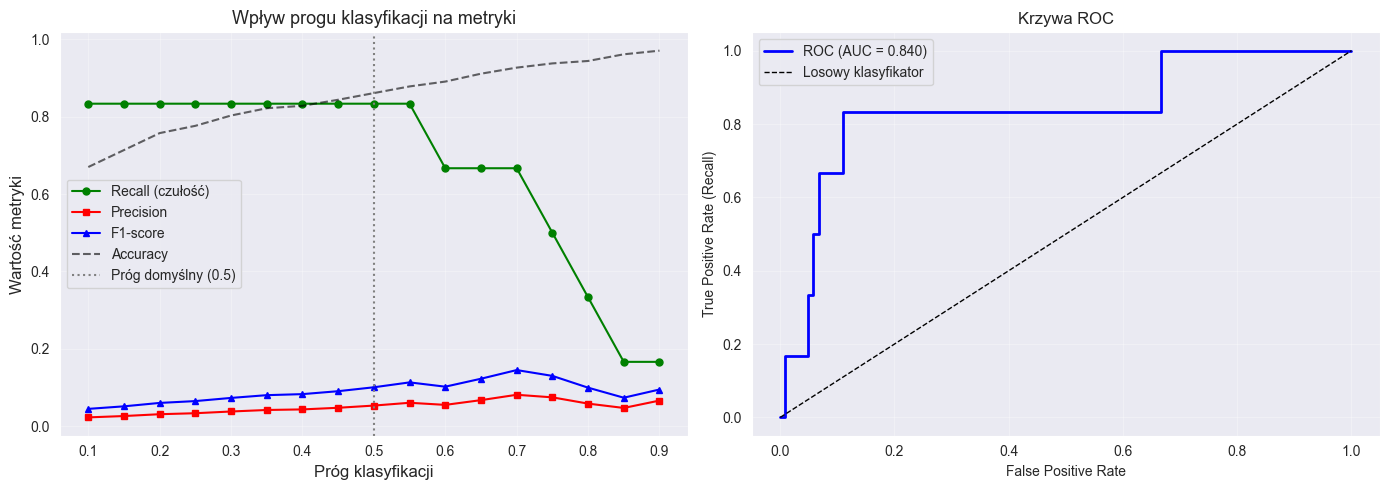

In [22]:
proba = log_reg.predict_proba(X_bk_te_sc)[:, 1]
thresholds = np.arange(0.1, 0.91, 0.05)

rec_list, prec_list, f1_list, acc_list = [], [], [], []
for t in thresholds:
    y_t = (proba >= t).astype(int)
    rec_list.append(recall_score(y_bk_te, y_t, zero_division=0))
    prec_list.append(precision_score(y_bk_te, y_t, zero_division=0))
    f1_list.append(f1_score(y_bk_te, y_t, zero_division=0))
    acc_list.append(accuracy_score(y_bk_te, y_t))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(thresholds, rec_list,  'g-o', ms=5, label='Recall (czułość)')
ax1.plot(thresholds, prec_list, 'r-s', ms=5, label='Precision')
ax1.plot(thresholds, f1_list,   'b-^', ms=5, label='F1-score')
ax1.plot(thresholds, acc_list,  'k--', ms=3, label='Accuracy', alpha=0.6)
ax1.axvline(0.5, color='gray', ls=':', lw=1.5, label='Próg domyślny (0.5)')
ax1.set_xlabel('Próg klasyfikacji', fontsize=12)
ax1.set_ylabel('Wartość metryki', fontsize=12)
ax1.set_title('Wpływ progu klasyfikacji na metryki', fontsize=13)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Krzywa ROC
fpr, tpr, _ = roc_curve(y_bk_te, proba)
roc_auc = auc(fpr, tpr)
ax2.plot(fpr, tpr, 'b-', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
ax2.plot([0,1],[0,1], 'k--', lw=1, label='Losowy klasyfikator')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate (Recall)')
ax2.set_title('Krzywa ROC')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Zadanie 2.4 – Wpływ parametru regularyzacji C: Ridge vs LASSO

> **C** to odwrotność siły regularyzacji: małe C = silna regularyzacja, duże C = słaba regularyzacja.
> **L2 (Ridge)** = wszystkie cechy, żadna nie jest zerowana
> **L1 (LASSO)** = agresywna selekcja cech  
> **Elastic Net** = kombinacja L1 i L2; parametr `l1_ratio`: 0 = Ridge, 1 = LASSO

C:\Users\cypri\SM_SI\uczenie_maszynowe\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\cypri\SM_SI\uczenie_maszynowe\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\cypri\SM_SI\uczenie_maszynowe\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\cypri\SM_SI\uczenie_maszynowe\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\cypri\SM_SI\uczenie_maszynowe\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\c

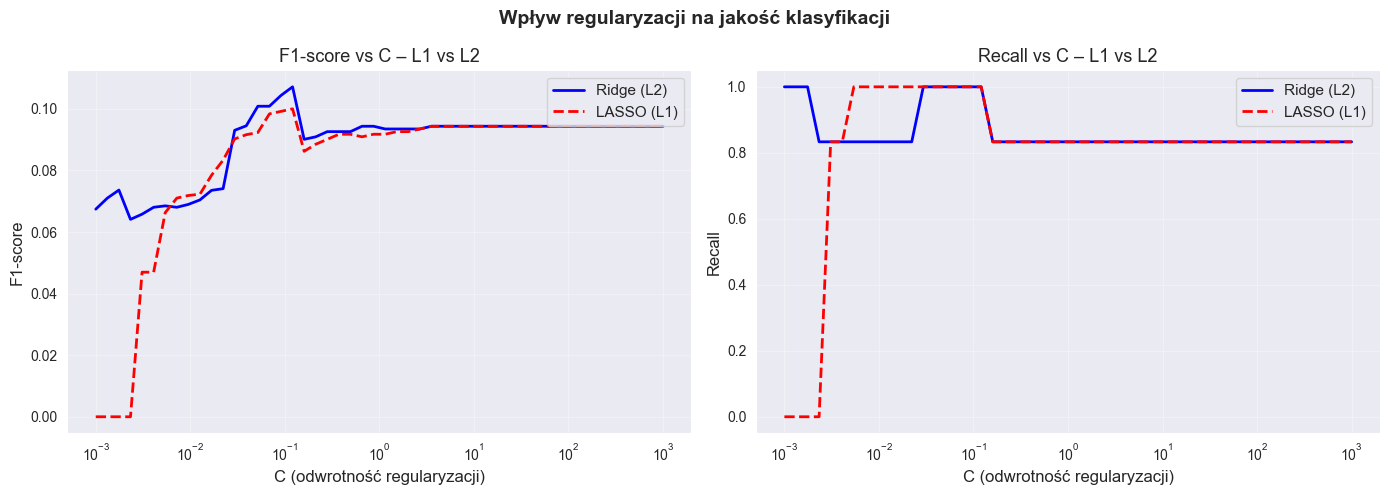

In [29]:
C_values = np.logspace(-3, 3, 50)

results = {'l2': {'f1': [], 'rec': []}, 'l1': {'f1': [], 'rec': []}}

for C in C_values:
    for l1_ratio, label in [(0.0, 'l2'), (1.0, 'l1')]:
        m = LogisticRegression(C=C,
                               l1_ratio=l1_ratio,
                               solver='saga',
                               class_weight='balanced',
                               max_iter=1000,
                               random_state=1)
        m.fit(X_bk_tr_sc, y_bk_tr)
        yp = m.predict(X_bk_te_sc)

        results[label]['f1'].append(f1_score(y_bk_te, yp, zero_division=0))
        results[label]['rec'].append(recall_score(y_bk_te, yp, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, label in zip(axes, ['f1', 'rec'], ['F1-score', 'Recall']):
    ax.semilogx(C_values, results['l2'][metric], 'b-', lw=2, label='Ridge (L2)')
    ax.semilogx(C_values, results['l1'][metric], 'r--', lw=2, label='LASSO (L1)')
    ax.set_xlabel('C (odwrotność regularyzacji)', fontsize=12)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label} vs C – L1 vs L2', fontsize=13)
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)

plt.suptitle('Wpływ regularyzacji na jakość klasyfikacji', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [30]:
# Elastic Net
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
C_en = 0.1

print('Elastic Net – wpływ l1_ratio')
print(f'{"l1_ratio":>10} | {"Recall":>8} | {"Precision":>10} | {"F1":>8} | {"Niezerowe wagi":>15}')
print('-' * 60)

for ratio in l1_ratios:
    m = LogisticRegression(C=C_en, solver='saga',
                           l1_ratio=ratio, class_weight='balanced',
                           max_iter=2000, random_state=1)
    m.fit(X_bk_tr_sc, y_bk_tr)
    yp = m.predict(X_bk_te_sc)
    n_nz = np.sum(np.abs(m.coef_[0]) > 1e-4)
    print(
        f'{ratio:>10.1f} | {recall_score(y_bk_te, yp, zero_division=0):>8.4f} | '
        f'{precision_score(y_bk_te, yp, zero_division=0):>10.4f} | '
        f'{f1_score(y_bk_te, yp, zero_division=0):>8.4f} | '
        f'{n_nz:>15d}'
    )

print('\nInterpretacja Elastic Net:')
print('l1_ratio=0 -> Ridge (L2): wszystkie cechy zachowane, brak zerowania')
print('l1_ratio=1 -> LASSO (L1): agresywna selekcja cech')
print('l1_ratio=0.5 -> kompromis: grupuje skorelowane cechy i dokonuje selekcji')

Elastic Net – wpływ l1_ratio
  l1_ratio |   Recall |  Precision |       F1 |  Niezerowe wagi
------------------------------------------------------------
       0.1 |   1.0000 |     0.0545 |   0.1034 |              62
       0.3 |   1.0000 |     0.0536 |   0.1017 |              54
       0.5 |   1.0000 |     0.0531 |   0.1008 |              48
       0.7 |   1.0000 |     0.0531 |   0.1008 |              41
       0.9 |   1.0000 |     0.0531 |   0.1008 |              31

Interpretacja Elastic Net:
l1_ratio=0 -> Ridge (L2): wszystkie cechy zachowane, brak zerowania
l1_ratio=1 -> LASSO (L1): agresywna selekcja cech
l1_ratio=0.5 -> kompromis: grupuje skorelowane cechy i dokonuje selekcji


---
# Zadanie 3 Geometria SVM

SVM (Support Vector Machine) szuka **hiperpłaszczyzny o maksymalnym marginesie** między klasami. Tylko punkty leżące najbliżej tej granicy – **wektory nośne** – definiują model.

> **Co to jest wektor nośny?** To punkt treningowy leżący na granicy marginesu. Usunięcie dowolnego innego punktu nie zmienia modelu – usunięcie wektora nośnego zmienia granice decyzyjną. SVM jest algorytmem **rzadkim** – rozwiązanie zależy wyłacznie od wektorów nośnych.

## Zadanie 3.1 & 3.2 – SVM z jądrem liniowym vs RBF na zbiorze WINE (klasyfikacja 3 klas)

In [31]:
X_wine_cls = wine.data
y_wine_cls = wine.target

X_w_tr, X_w_te, y_w_tr, y_w_te = train_test_split(
    X_wine_cls, y_wine_cls, test_size=0.2, random_state=42, stratify=y_wine_cls
)
sc_w = StandardScaler()
X_w_tr_sc = sc_w.fit_transform(X_w_tr)
X_w_te_sc  = sc_w.transform(X_w_te)

print('Porównanie jąder SVM')
print(f'{"Jądro":>10} | {"C":>6} | {"Accuracy":>10} | {"Wektory nośne":>15}')
print('-' * 50)

for kernel in ['linear', 'rbf']:
    for C_val in [0.1, 1.0, 10.0]:
        svm = SVC(kernel=kernel, C=C_val, random_state=42)
        svm.fit(X_w_tr_sc, y_w_tr)
        acc = accuracy_score(y_w_te, svm.predict(X_w_te_sc))
        n_sv = svm.support_vectors_.shape[0]
        print(f'{kernel:>10} | {C_val:>6.1f} | {acc:>10.4f} | {n_sv:>15d}')

print('\nObserwacja: Jądro RBF daje większe dokładności kosztem większej liczby wektorów nośnych.')
print('Nieliniowe jądro RBF potrafi uchwycić zakrzywione granice między klasami win.')

Porównanie jąder SVM
     Jądro |      C |   Accuracy |   Wektory nośne
--------------------------------------------------
    linear |    0.1 |     0.9722 |              37
    linear |    1.0 |     0.9444 |              27
    linear |   10.0 |     0.9444 |              27
       rbf |    0.1 |     0.9722 |             124
       rbf |    1.0 |     0.9722 |              61
       rbf |   10.0 |     0.9444 |              57

Obserwacja: Jądro RBF daje większe dokładności kosztem większej liczby wektorów nośnych.
Nieliniowe jądro RBF potrafi uchwycić zakrzywione granice między klasami win.


## Zadanie 3.3 – Wizualizacja granic decyzyjnych (2 cechy)

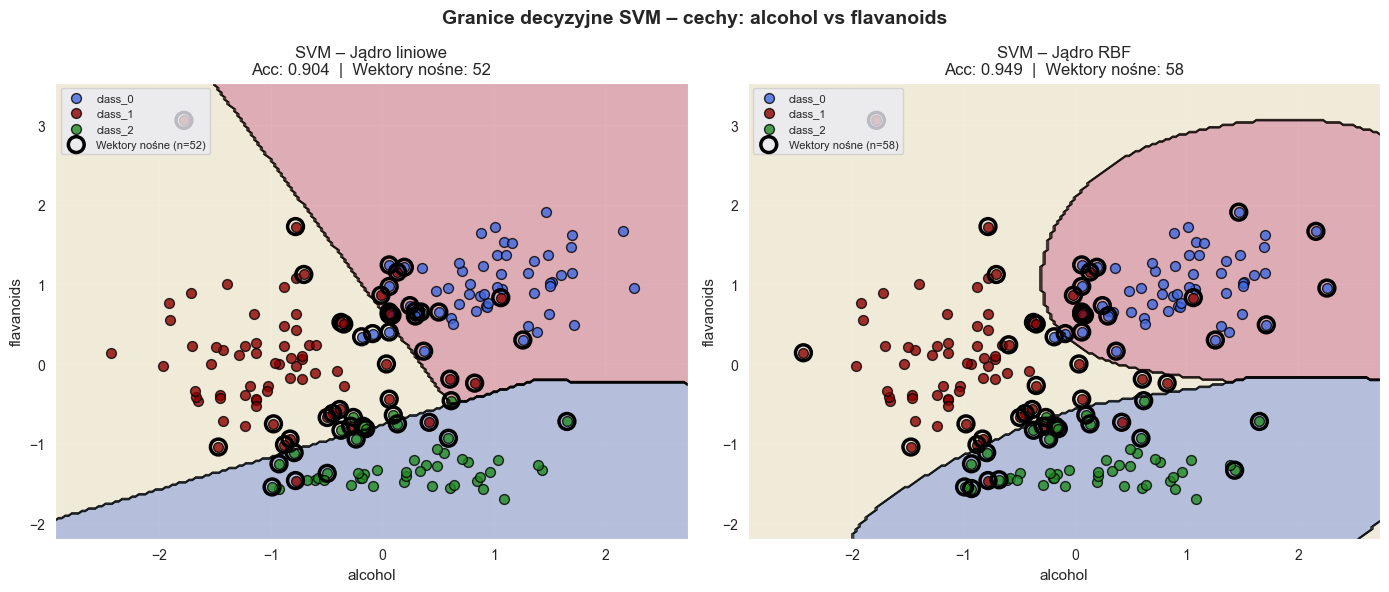

Jądro liniowe: granice sa prostymi liniami (hiperpłaszczyzny w oryginalnej przestrzeni)
Jądro RBF: granice sa KRZYWE (model nieliniowy, dziala w przestrzeni jądrowej)
Kółka bez wypełnienia = wektory nośne – jedyne punkty definiujące margines


In [32]:
# Wybieramy 2 cechy: alcohol (idx 0) i flavanoids (idx 6) – dobrze separują klasy
feat_idx = [0, 6]
feat_labels = [wine.feature_names[i] for i in feat_idx]

X_2d    = wine.data[:, feat_idx]
y_2d    = wine.target
sc_2d   = StandardScaler()
X_2d_sc = sc_2d.fit_transform(X_2d)

h = 0.03
x_min, x_max = X_2d_sc[:, 0].min() - 0.5, X_2d_sc[:, 0].max() + 0.5
y_min2, y_max2 = X_2d_sc[:, 1].min() - 0.5, X_2d_sc[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min2, y_max2, h))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
pt_colors = ['royalblue', 'darkred', 'forestgreen']

for ax, (kernel, label) in zip(axes, [('linear', 'Jądro liniowe'), ('rbf', 'Jądro RBF')]):
    svm_2d = SVC(kernel=kernel, C=1.0, random_state=1)
    svm_2d.fit(X_2d_sc, y_2d)

    Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.RdYlBu)
    ax.contour(xx, yy, Z, colors='black', linewidths=0.5)

    for cls_idx, col in enumerate(pt_colors):
        mask = y_2d == cls_idx
        ax.scatter(X_2d_sc[mask, 0], X_2d_sc[mask, 1],
                   c=col, edgecolors='k', s=50, alpha=0.8,
                   label=f'{wine.target_names[cls_idx]}')

    sv = svm_2d.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=130, facecolors='none', edgecolors='black',
               linewidths=2.5, label=f'Wektory nośne (n={len(sv)})')

    acc_2d = accuracy_score(y_2d, svm_2d.predict(X_2d_sc))
    ax.set_xlabel(feat_labels[0], fontsize=11)
    ax.set_ylabel(feat_labels[1], fontsize=11)
    ax.set_title(f'SVM – {label}\nAcc: {acc_2d:.3f}  |  Wektory nośne: {len(sv)}', fontsize=12)
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(True, alpha=0.2)

plt.suptitle(f'Granice decyzyjne SVM – cechy: {feat_labels[0]} vs {feat_labels[1]}',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Jądro liniowe: granice sa prostymi liniami (hiperpłaszczyzny w oryginalnej przestrzeni)')
print('Jądro RBF: granice sa KRZYWE (model nieliniowy, dziala w przestrzeni jądrowej)')
print('Kółka bez wypełnienia = wektory nośne – jedyne punkty definiujące margines')

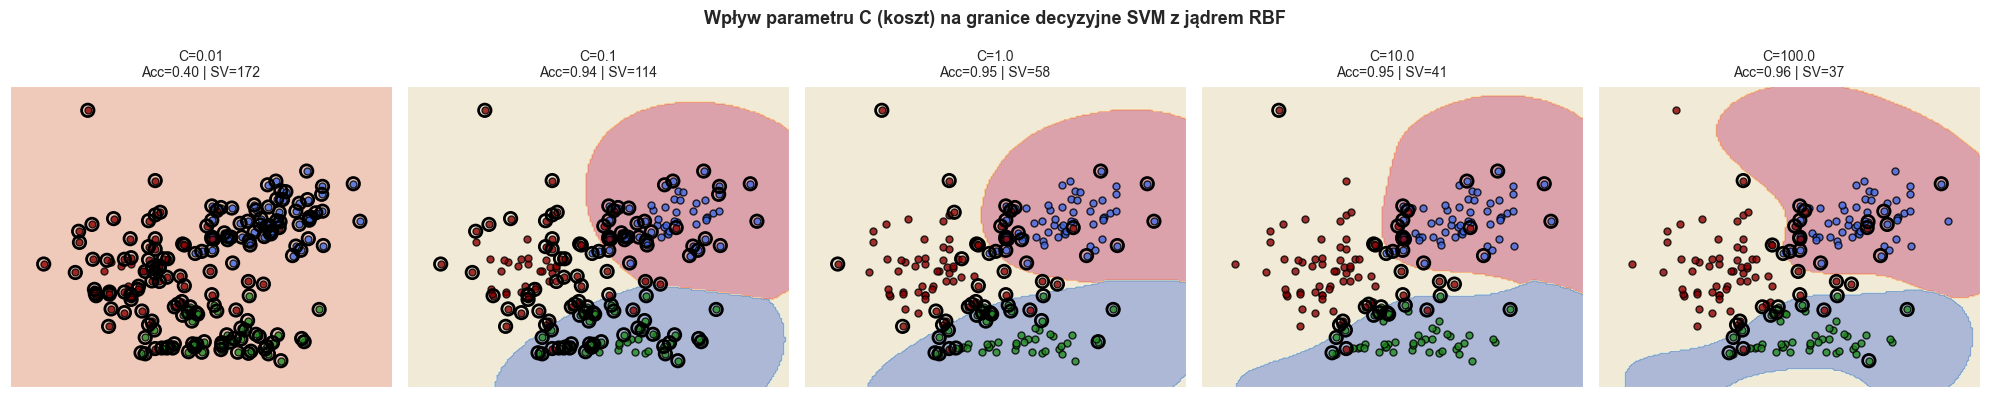

Małe C = szeroki margines, więcej błędów treningowych (underfitting)
Duże C = wąski margines, model stara sie poprawnie klasyfikowac wszystkie punkty (overfitting)


In [33]:
# Wplyw parametru C na margines – wizualizacja
C_list = [0.01, 0.1, 1.0, 10.0, 100.0]

fig, axes = plt.subplots(1, len(C_list), figsize=(20, 4))

for ax, C_val in zip(axes, C_list):
    svm_c = SVC(kernel='rbf', C=C_val, random_state=1)
    svm_c.fit(X_2d_sc, y_2d)
    Z = svm_c.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.35, cmap=plt.cm.RdYlBu)

    for cls_idx, col in enumerate(pt_colors):
        mask = y_2d == cls_idx
        ax.scatter(X_2d_sc[mask, 0], X_2d_sc[mask, 1],
                   c=col, edgecolors='k', s=25, alpha=0.8)

    sv = svm_c.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=80, facecolors='none', edgecolors='black', lw=2)
    acc_c = accuracy_score(y_2d, svm_c.predict(X_2d_sc))
    ax.set_title(f'C={C_val}\nAcc={acc_c:.2f} | SV={len(sv)}', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('Wpływ parametru C (koszt) na granice decyzyjne SVM z jądrem RBF',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Małe C = szeroki margines, więcej błędów treningowych (underfitting)')
print('Duże C = wąski margines, model stara sie poprawnie klasyfikowac wszystkie punkty (overfitting)')

## Odpowiedzi na pytania pomocnicze

### 1. Dlaczego skalowanie jest krytyczne dla Lasso/Ridge, a mniej ważne dla drzew decyzyjnych?
Regularyzacja Ridge/LASSO nakłada kare na **wartości bezwzględne** współczynników. Cecha mierzona w gramach dostanie proporcjonalnie mniejszy współczynnik niż cecha w procentach, co wypaczy selekcje. StandardScaler wyrównuje jednostki. **Drzewa decyzyjne** dzielą dane po progach – nie interesują ich wartości współczynnikow, tylko porządek wartości.

### 2. Czym różni się minimalizacja błędu L1 od L2?
- **L2 (Ridge)**: minimalizuje sume kwadratów współczynników – kara rośnie *kwadratowo* z odległością od zera. Wszystkie wagi maleją płynnie, żadna nie osiaga dokladnie 0. Geometrycznie: zbiór ograniczeń to kula.
- **L1 (LASSO)**: minimalizuje sume wartości bezwzględnych – kara rośnie *liniowo*. Pochodna jest stala (+/-1), więc optymalizator może "wcisnąć" wage dokladnie do zera. Dokonuje **selekcji cech**. Geometrycznie: zbiór ograniczeń to romb z rogami na osiach współrzędnych.

### 3. Dlaczego accuracy jest mylące przy niezbalansowanych danych?
Jeśli bankruci stanowią 5% zbioru, model klasyfikujacy *wszystkich jako nie brankrutów* osiągnie **95% accuracy** – ale nie wykryje ani jednego bankruta (Recall = 0)! **Analiza progu prawdopodobieństwa** pozwala dostosować kompromis Precision–Recall do kontekstu: bank moze preferować wyzszy Recall (nie przeoczmy bankruta), nawet kosztem Precision (wiecej falszywych alarmów).

### 4. Co oznacza, ze punkt jest wektorem nośnym?
Wektor nośny to punkt treningowy leżący na granicy marginesu (lub po złej stronie przy soft-margin SVM z C<inf). To jedyne punkty, które **aktywnie wplywają** na pozycje granicy decyzyjnej – mają niezerowe mnożniki Lagrange'a w dualnym sformulowaniu problemu. Usunięcie dowolnego innego punktu treningowego nie zmienia modelu. Stąd nazwa: SVM to algorytm **rzadki**, bo rozwiązanie jest kombinacją liniową tylko wektorów nośnych.